# 📊 Exploratory Data Analysis — Server Machine Dataset (SMD)

**Project:** Anomaly Detection in Sensor / IoT Time Series Data  
**Dataset:** Server Machine Dataset (SMD)  
**Source:** [OmniAnomaly/GitHub](https://github.com/NetManAIOps/OmniAnomaly)  
**Week:** 1 — Foundation  

---

## Objectives

1. **Dataset Documentation** — Source, version, machine count, feature count, row counts
2. **Basic Statistics** — Mean, std, min/max, quartiles per sensor
3. **Missing Data Analysis** — NaN/null values, gaps
4. **Distribution Analysis** — Histograms/KDE per sensor
5. **Time-Series Visualization** — Raw sensor readings with anomaly windows
6. **Correlation Analysis** — Inter-sensor correlation heatmap
7. **Anomaly Label Analysis** — Class distribution (normal vs. anomalous)
8. **Train/Test Distribution Comparison** — Check for distributional shift

In [1]:
# ── Setup ────────────────────────────────────────
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project modules
from src.data_loader import load_smd_machine, get_dataset_info, load_as_dataframe, NUM_FEATURES
from src.config import load_config

# Plotting style
plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.family'] = 'sans-serif'

print(f'NumPy: {np.__version__}')
print(f'Pandas: {pd.__version__}')
print(f'Features per machine: {NUM_FEATURES}')

NumPy: 2.4.6
Pandas: 3.0.5
Features per machine: 38


## 1. Dataset Documentation

PRD §6 requires documenting the exact schema from the actual downloaded dataset.

In [2]:
# ── Dataset Info ──────────────────────────────────
info = get_dataset_info()
print(f"Dataset Name: {info['name']}")
print(f"Status: {info['status']}")
print(f"Number of Features: {info['num_features']}")
print(f"Total Machines: {info.get('total_machines', 'N/A')}")
print(f"Label Format: {info['label_format']}")
print(f"Source: {info['source']}")

if info['machines']:
    machines_df = pd.DataFrame(info['machines'])
    print(f"\n--- Machine Summary ---")
    display(machines_df)

Dataset Name: Server Machine Dataset (SMD)
Status: available
Number of Features: 38
Total Machines: 27
Label Format: Binary (0=normal, 1=anomaly)
Source: https://github.com/NetManAIOps/OmniAnomaly

--- Machine Summary ---


,machine_id,n_train,n_test,anomaly_count,anomaly_ratio
0,machine-1-1,28479,28479,2694,0.094596
1,machine-1-2,23694,23694,542,0.022875
2,machine-1-3,23702,23703,817,0.034468
3,machine-1-4,23706,23707,720,0.030371
4,machine-1-5,23705,23706,100,0.004218
5,machine-1-6,23688,23689,3708,0.156528
6,machine-1-7,23697,23697,2398,0.101194
7,machine-1-8,23698,23699,763,0.032195
8,machine-2-1,23693,23694,1170,0.049380
9,machine-2-2,23699,23700,2833,0.119536


## 2. Load Primary Machine Data

We'll focus on `machine-1-1` as the primary machine for initial EDA and model development.

In [3]:
# ── Load data for primary machine ──────────────────
config = load_config()
MACHINE_ID = config.dataset.machine_id
print(f"Primary machine: {MACHINE_ID}")

data = load_smd_machine(MACHINE_ID)

print(f"\n--- Data Shapes ---")
print(f"Train: {data['train'].shape}")
print(f"Test:  {data['test'].shape}")
print(f"Test Labels: {data['test_labels'].shape}")
print(f"Num Features: {data['num_features']}")
print(f"Anomaly Ratio (test): {data['anomaly_ratio']:.4f} ({data['anomaly_ratio']*100:.2f}%)")

# Load as DataFrames for analysis
train_df = load_as_dataframe(MACHINE_ID, split='train')
test_df = load_as_dataframe(MACHINE_ID, split='test')

Primary machine: machine-1-1

--- Data Shapes ---
Train: (28479, 38)
Test:  (28479, 38)
Test Labels: (28479,)
Num Features: 38
Anomaly Ratio (test): 0.0946 (9.46%)


## 3. Basic Statistics

In [4]:
# ── Descriptive statistics for train data ─────────
print("=== TRAINING DATA ===\n")
display(train_df.describe().T)

=== TRAINING DATA ===



,count,mean,std,min,25%,50%,75%,max
sensor_0,28479.0,0.064195,0.056685,0.000000,0.032258,0.043011,0.086022,0.494624
sensor_1,28479.0,0.056882,0.042516,0.000000,0.027542,0.045551,0.075212,0.421610
sensor_2,28479.0,0.053549,0.037695,0.000000,0.027871,0.042363,0.070234,0.278707
sensor_3,28479.0,0.050188,0.037443,0.000000,0.024390,0.037166,0.067364,0.250871
sensor_4,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
sensor_5,28479.0,0.913552,0.037972,0.000000,0.907692,0.912821,0.920513,1.000000
sensor_6,28479.0,0.262274,0.066661,0.000000,0.251412,0.274011,0.311676,0.360640
sensor_7,28479.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
sensor_8,28479.0,0.020346,0.009982,0.000000,0.012347,0.021005,0.027959,0.118081
sensor_9,28479.0,0.000159,0.001287,0.000000,0.000000,0.000000,0.000122,0.140435


In [ ]:
# ── Descriptive statistics for test data ──────────
print("=== TEST DATA ===\n")
display(test_df.describe().T)

## 4. Missing Data Analysis

In [5]:
# ── Check for missing values ──────────────────────
train_missing = train_df.isnull().sum()
test_missing = test_df.isnull().sum()

print(f"Training data missing values: {train_missing.sum()}")
print(f"Test data missing values: {test_missing.sum()}")

if train_missing.sum() > 0:
    print("\nSensors with missing values (train):")
    print(train_missing[train_missing > 0])
else:
    print("\n✅ No missing values in training data.")

# Check for infinite values
sensor_cols = [c for c in train_df.columns if c.startswith('sensor_')]
train_inf = np.isinf(train_df[sensor_cols]).sum().sum()
test_inf = np.isinf(test_df[sensor_cols]).sum().sum()
print(f"\nInfinite values — Train: {train_inf}, Test: {test_inf}")

Training data missing values: 0
Test data missing values: 0

✅ No missing values in training data.

Infinite values — Train: 0, Test: 0


## 5. Distribution Analysis

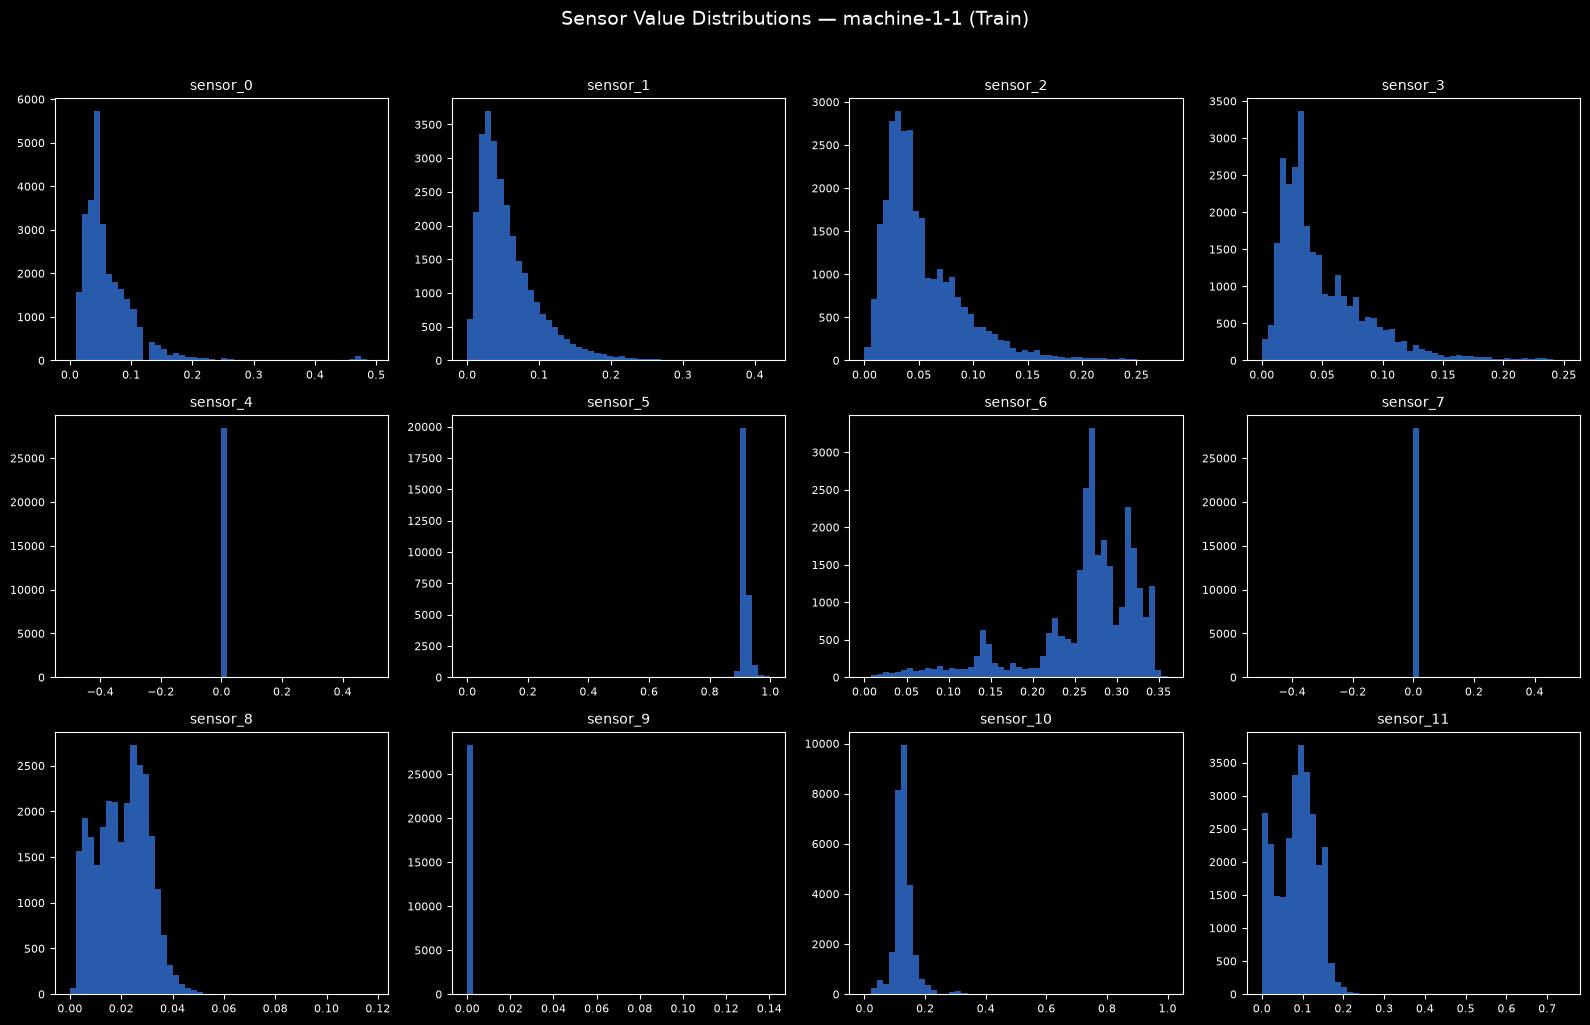

In [6]:
# ── Sensor value distributions (first 12 sensors) ─
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
fig.suptitle(f'Sensor Value Distributions — {MACHINE_ID} (Train)', fontsize=14, y=1.02)

for i, ax in enumerate(axes.flat):
    if i < 12:
        col = f'sensor_{i}'
        ax.hist(train_df[col], bins=50, alpha=0.7, color='#3b82f6', edgecolor='none')
        ax.set_title(col, fontsize=10)
        ax.tick_params(labelsize=8)
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()

## 6. Time-Series Visualization with Anomaly Windows

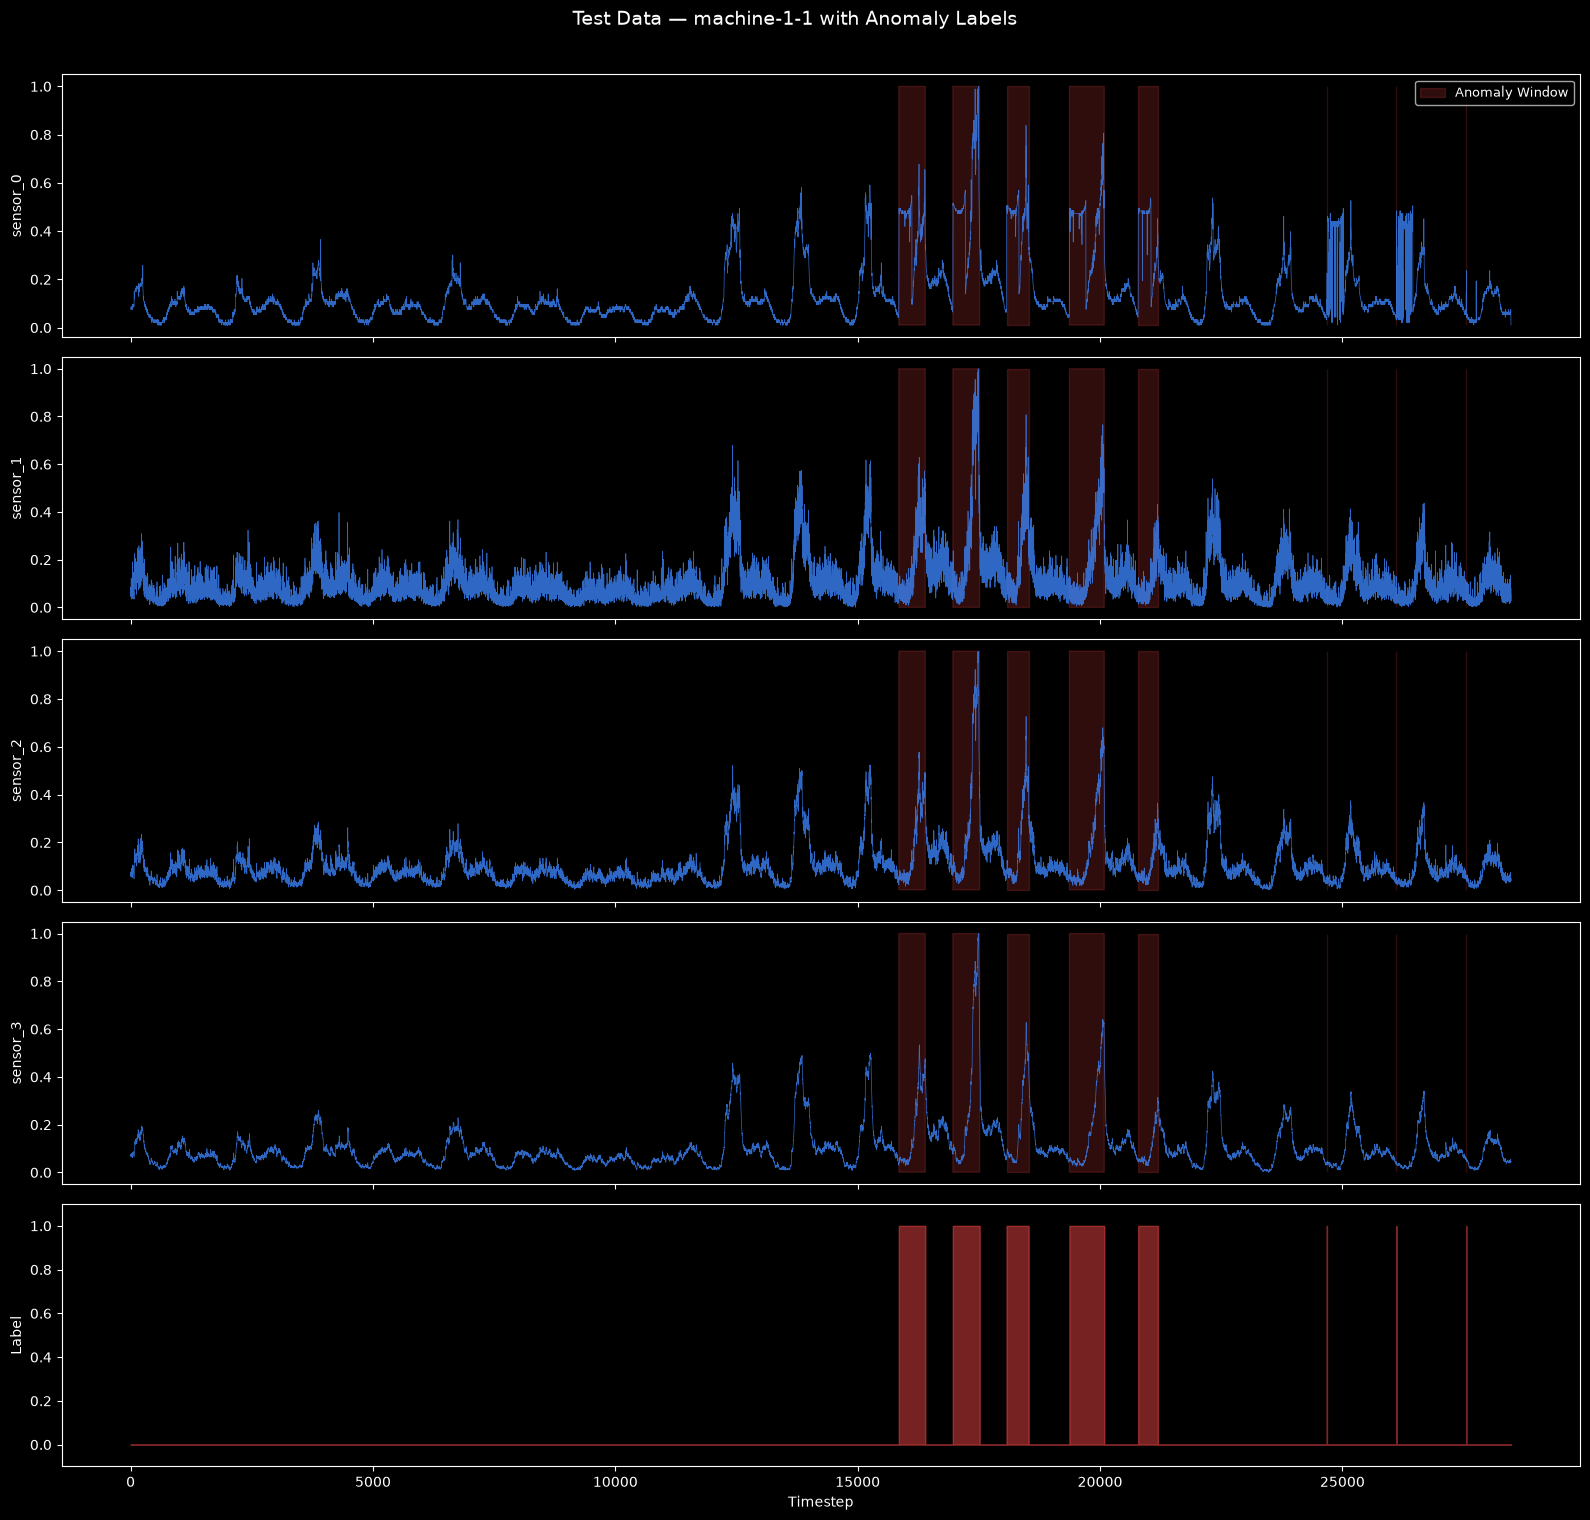

In [7]:
# ── Plot sensor readings over time (test set with labels) ─
sensors_to_plot = ['sensor_0', 'sensor_1', 'sensor_2', 'sensor_3']
n_sensors = len(sensors_to_plot)

fig, axes = plt.subplots(n_sensors + 1, 1, figsize=(16, 3 * (n_sensors + 1)), sharex=True)
fig.suptitle(f'Test Data — {MACHINE_ID} with Anomaly Labels', fontsize=14, y=1.01)

# Anomaly regions
anomaly_mask = test_df['label'] == 1

for i, sensor in enumerate(sensors_to_plot):
    ax = axes[i]
    ax.plot(test_df['timestep'], test_df[sensor], linewidth=0.5, color='#3b82f6', alpha=0.8)
    ax.fill_between(
        test_df['timestep'], test_df[sensor].min(), test_df[sensor].max(),
        where=anomaly_mask, alpha=0.2, color='#ef4444', label='Anomaly Window'
    )
    ax.set_ylabel(sensor, fontsize=10)
    if i == 0:
        ax.legend(loc='upper right', fontsize=9)

# Labels subplot
axes[-1].fill_between(
    test_df['timestep'], 0, test_df['label'],
    alpha=0.5, color='#ef4444', step='mid'
)
axes[-1].set_ylabel('Label', fontsize=10)
axes[-1].set_xlabel('Timestep', fontsize=10)
axes[-1].set_ylim(-0.1, 1.1)

plt.tight_layout()
plt.show()

## 7. Correlation Analysis

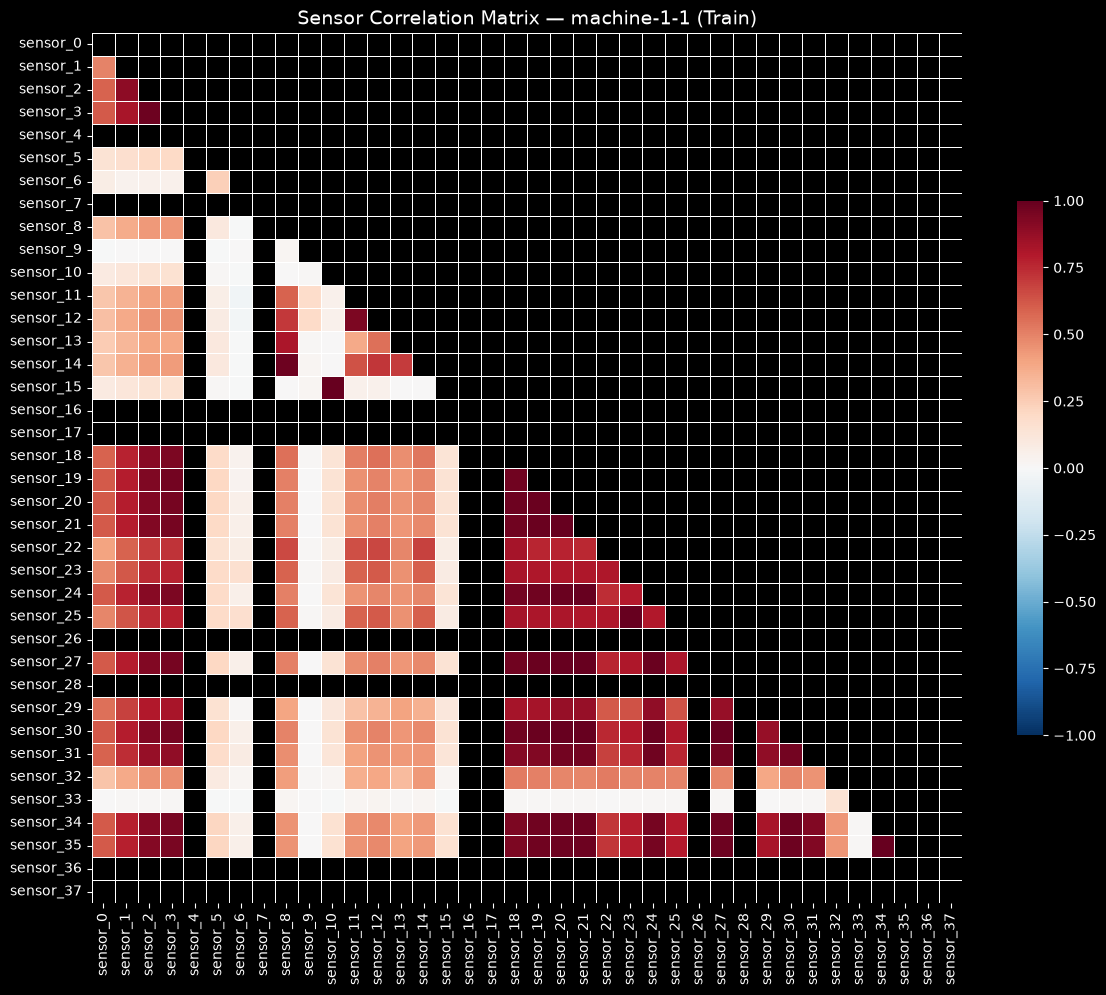


Highly correlated sensor pairs (|r| > 0.8): 101
  sensor_34 ↔ sensor_35: r = 1.000
  sensor_21 ↔ sensor_30: r = 1.000
  sensor_20 ↔ sensor_27: r = 1.000
  sensor_27 ↔ sensor_30: r = 1.000
  sensor_20 ↔ sensor_21: r = 0.999
  sensor_20 ↔ sensor_30: r = 0.999
  sensor_21 ↔ sensor_27: r = 0.999
  sensor_23 ↔ sensor_25: r = 0.999
  sensor_10 ↔ sensor_15: r = 0.997
  sensor_21 ↔ sensor_24: r = 0.994


In [8]:
# ── Inter-sensor correlation heatmap ──────────────
corr_matrix = train_df[sensor_cols].corr()

fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='RdBu_r',
    center=0,
    vmin=-1, vmax=1,
    ax=ax,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.6},
)
ax.set_title(f'Sensor Correlation Matrix — {MACHINE_ID} (Train)', fontsize=14)
plt.tight_layout()
plt.show()

# High correlations
upper = corr_matrix.where(mask == False)
high_corr = [
    (col, idx, upper.loc[idx, col])
    for col in upper.columns
    for idx in upper.index
    if abs(upper.loc[idx, col]) > 0.8 and col != idx
]
if high_corr:
    print(f"\nHighly correlated sensor pairs (|r| > 0.8): {len(high_corr)}")
    for s1, s2, r in sorted(high_corr, key=lambda x: abs(x[2]), reverse=True)[:10]:
        print(f"  {s1} ↔ {s2}: r = {r:.3f}")

## 8. Anomaly Label Analysis

=== Anomaly Label Distribution (Test Set) ===
Normal:    25,785 (90.54%)
Anomalous: 2,694 (9.46%)
Total:     28,479
Imbalance ratio: 1:9.6


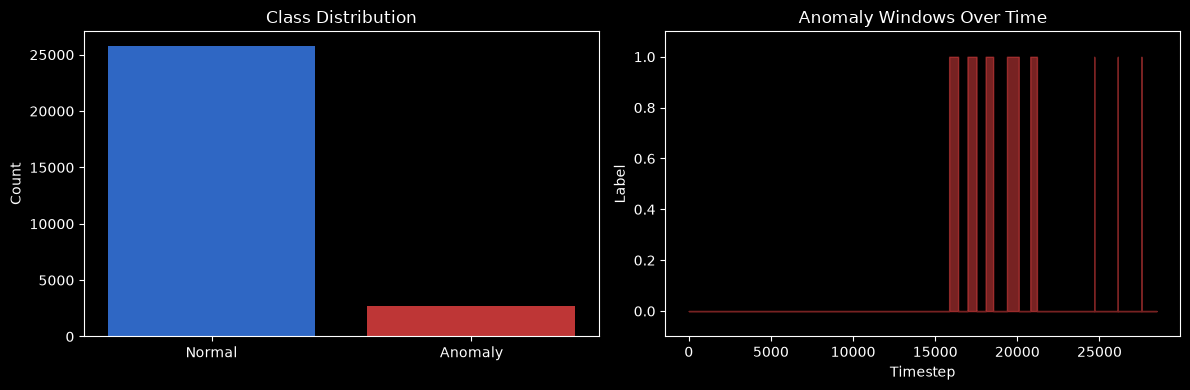

In [9]:
# ── Class distribution ────────────────────────────
n_normal = (test_df['label'] == 0).sum()
n_anomaly = (test_df['label'] == 1).sum()
total = len(test_df)

print(f"=== Anomaly Label Distribution (Test Set) ===")
print(f"Normal:    {n_normal:,} ({n_normal/total*100:.2f}%)")
print(f"Anomalous: {n_anomaly:,} ({n_anomaly/total*100:.2f}%)")
print(f"Total:     {total:,}")
print(f"Imbalance ratio: 1:{n_normal/max(n_anomaly, 1):.1f}")

# Visualize
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
ax1.bar(['Normal', 'Anomaly'], [n_normal, n_anomaly],
        color=['#3b82f6', '#ef4444'], edgecolor='none', alpha=0.8)
ax1.set_title('Class Distribution', fontsize=12)
ax1.set_ylabel('Count')

# Anomaly windows timeline
ax2.fill_between(range(total), 0, test_df['label'].values,
                 alpha=0.5, color='#ef4444', step='mid')
ax2.set_title('Anomaly Windows Over Time', fontsize=12)
ax2.set_xlabel('Timestep')
ax2.set_ylabel('Label')
ax2.set_ylim(-0.1, 1.1)

plt.tight_layout()
plt.show()

## 9. Train/Test Distribution Comparison

Verify there is no major distributional shift between train and test sets.

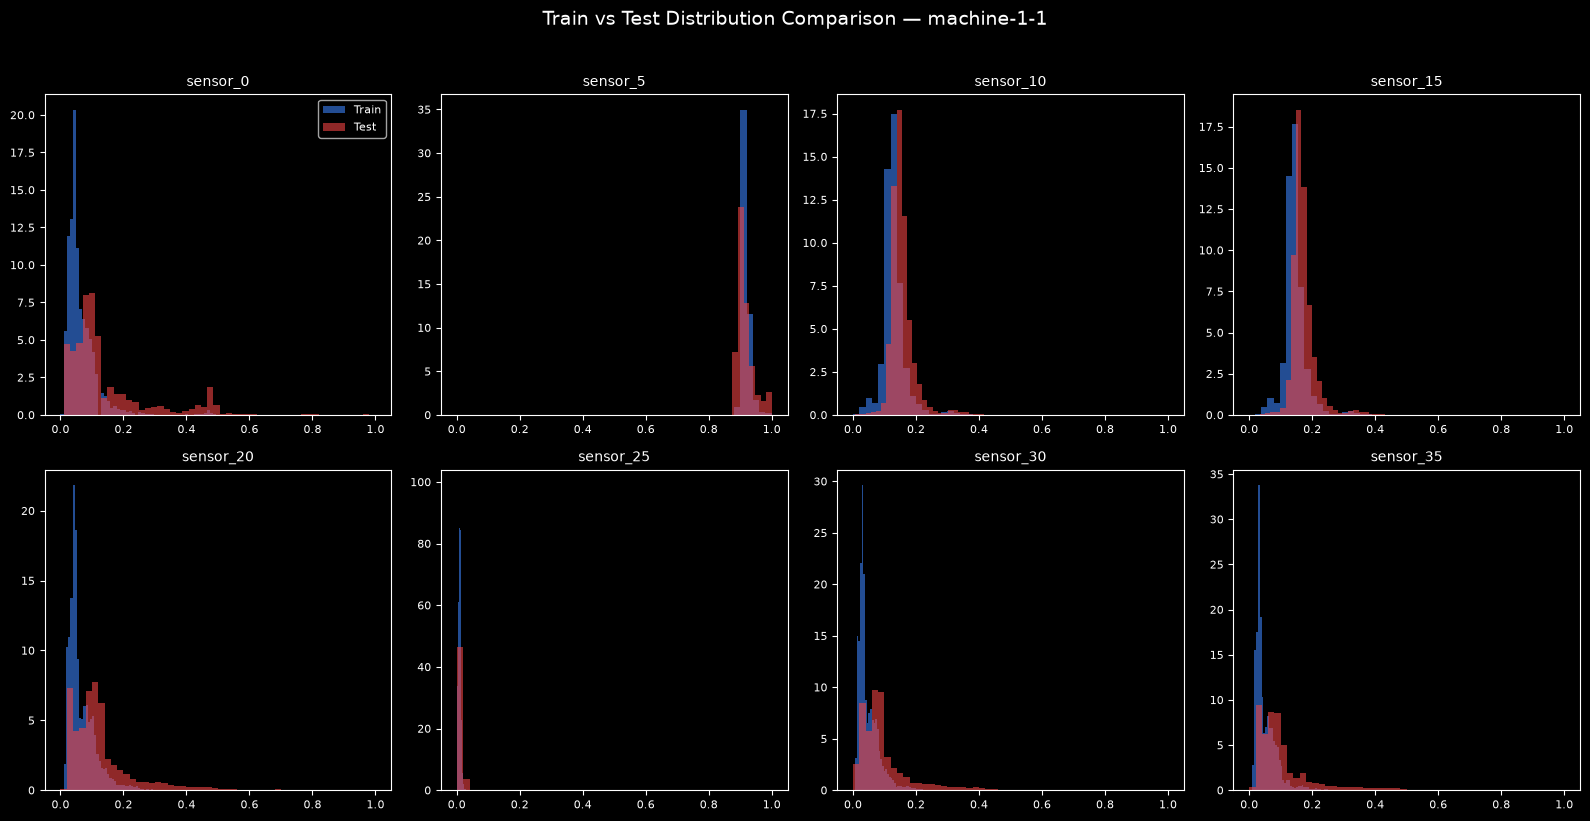

In [10]:
# ── Train vs Test distributions for key sensors ──
sensors_to_compare = ['sensor_0', 'sensor_5', 'sensor_10', 'sensor_15',
                      'sensor_20', 'sensor_25', 'sensor_30', 'sensor_35']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle(f'Train vs Test Distribution Comparison — {MACHINE_ID}', fontsize=14, y=1.02)

for i, (ax, sensor) in enumerate(zip(axes.flat, sensors_to_compare)):
    ax.hist(train_df[sensor], bins=50, alpha=0.6, label='Train',
            color='#3b82f6', density=True, edgecolor='none')
    ax.hist(test_df[sensor], bins=50, alpha=0.6, label='Test',
            color='#ef4444', density=True, edgecolor='none')
    ax.set_title(sensor, fontsize=10)
    ax.tick_params(labelsize=8)
    if i == 0:
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 10. Preprocessing Pipeline Verification

Verify that the preprocessing pipeline is leakage-safe.

In [11]:
# ── Test the preprocessing pipeline ───────────────
from src.preprocessing import preprocess_pipeline

result = preprocess_pipeline(
    train_raw=data['train'],
    test_raw=data['test'],
    test_labels=data['test_labels'],
    window_size=config.preprocessing.window_size,
    step_size=config.preprocessing.step_size,
    val_split=config.preprocessing.val_split,
    scaler_method=config.preprocessing.scaler,
    seed=config.training.seed,
)

print("=== Preprocessing Pipeline Output ===")
print(f"Train windows: {result['train_windows'].shape}")
print(f"Val windows:   {result['val_windows'].shape}")
print(f"Test windows:  {result['test_windows'].shape}")
print(f"Test labels:   {result['test_window_labels'].shape}")
print(f"")
print(f"Config: {result['config']}")

# Verify scaler was fit on train only
scaler = result['scaler']
print(f"\nScaler mean (first 5): {scaler.mean_[:5]}")
print(f"Scaler std (first 5):  {scaler.scale_[:5]}")
print(f"\n✅ Scaler fitted on {result['config']['n_train']} training samples only (leakage-safe).")

=== Preprocessing Pipeline Output ===
Train windows: (22754, 30, 38)
Val windows:   (5667, 30, 38)
Test windows:  (28450, 30, 38)
Test labels:   (28450,)

Config: {'window_size': 30, 'step_size': 1, 'val_split': 0.2, 'scaler_method': 'standard', 'seed': 42, 'n_train': 22783, 'n_val': 5696, 'n_test': 28479}

Scaler mean (first 5): [0.0580427  0.05012803 0.04644121 0.0427773  0.        ]
Scaler std (first 5):  [0.05762757 0.03827721 0.03347383 0.03309154 1.        ]

✅ Scaler fitted on 22783 training samples only (leakage-safe).


## Summary

### Dataset Characteristics
- **Name**: Server Machine Dataset (SMD)
- **Features**: 38 sensor channels per machine
- **Label format**: Binary (0=normal, 1=anomaly)
- **Training data**: Normal operation only
- **Test data**: Contains both normal and anomalous segments

### Key Findings
- [Document actual findings after running the notebook]
- Missing values: [To be documented]
- Anomaly ratio: [To be documented]
- High correlations: [To be documented]
- Distribution shift: [To be documented]

### Next Steps (Week 2)
- Build statistical baseline detector (z-score / moving average)
- Begin LSTM autoencoder architecture design
- Document baseline F1/precision/recall